# Streaming 실습: 요청 전 진행 값을 켜고 끄며 자료실 문의 답 흘려 보이기

**이 노트북에서 할 일**

1. 01~03절의 모드 목록, 진행 값, 스트림 청크 이어 붙이기, 사건마다 시각 적기를 그래프 하나에 모읍니다.
2. 자료실 문의 하나를 실행하며, 화면에 띄울 진행 값과 답 글을 사건 차례대로 기록합니다.
3. 같은 설정으로 한 번 더 실행한 뒤, 모델 요청 전 진행 값 하나만 끄고 세 실행을 견줍니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 모델 요청은 5·6·7절에서 한 번씩, 모두 3번입니다.
요금표로 어림한 예상 비용은 세 요청을 합쳐 0.002달러 아래이고, 청구 금액이 아닙니다.
걸린 시간은 03절 함수로 재지만, 초와 답 글, 스트림 청크 수는 실행마다 달라질 수 있습니다.
그래서 세 실행을 견줄 때는 사건의 모드와 자리를 봅니다.

읽거나 쓰는 파일은 없고, 체크포인터도 쓰지 않습니다.
앞에서 배운 함수 다섯은 도구 파일 `stream_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 넷을 설치합니다.
판은 langchain 1.4.0과 langchain-openai 1.6.0입니다.
langgraph 1.2.11과 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**실습 범위** — 이 절은 챕터 끝 실습 절이고 30분 안에 끝나는 분량입니다.
강사와 함께 첫 셀부터 차례로 실행하고, 따로 내는 과제는 없습니다.
01~03절에서 쓴 이름과 Ch 2에서 배운 문법만 씁니다.
실행 셀 하나만 다시 실행하면 모델 요청이 한 번 더 나가고, 사건 수와 초가 달라질 수 있습니다.

실습 폴더 `labs/part6/ch25-streaming`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 문의 글 한 줄 칸 show_notice yes가 회색 상자 graph.stream 01절 모드 셋 목록 요청 한 번을 거쳐 파란 상자 노드 answer_inquiry 02절 진행 값 30과 100, 30은 yes일 때만으로 이어집니다. 노드에서 보라 상자 모델 gpt-5.4-mini 노드 안 invoke 한 번으로 화살표가 갑니다. 노드는 진행 값과 갱신을, 모델은 스트림 청크를 파란 상자 03절 collect_timed_events 사건마다 시각 하나로 보냅니다. 그 아래 파란 상자 기록 장치 print_report screen_log mode_order first_text_place를 거쳐 노란 상자 화면 흐름 출력 모드 차례 첫 글자 자리 진행 값 화면 글과 답 글로 이어지는 그림](attachment:04-1-세-절-기능을-붙인-문의-그래프.png)

위에서 아래로 읽습니다.
초록 상자는 넣은 입력, 회색 상자는 라이브러리 메서드, 파란 상자는 우리가 적은 노드와 함수입니다.
보라 상자는 실제로 부른 모델이고, 노란 상자는 노트북 5~7절 기록 장치의 출력입니다.
상자 안의 절 번호는 그 기능을 배운 절이고, 진행 값과 갱신은 노드에서, 스트림 청크는 모델에서 옵니다.
노란 상자의 첫 글자 자리는 글자가 든 첫 스트림 청크의 자리입니다.
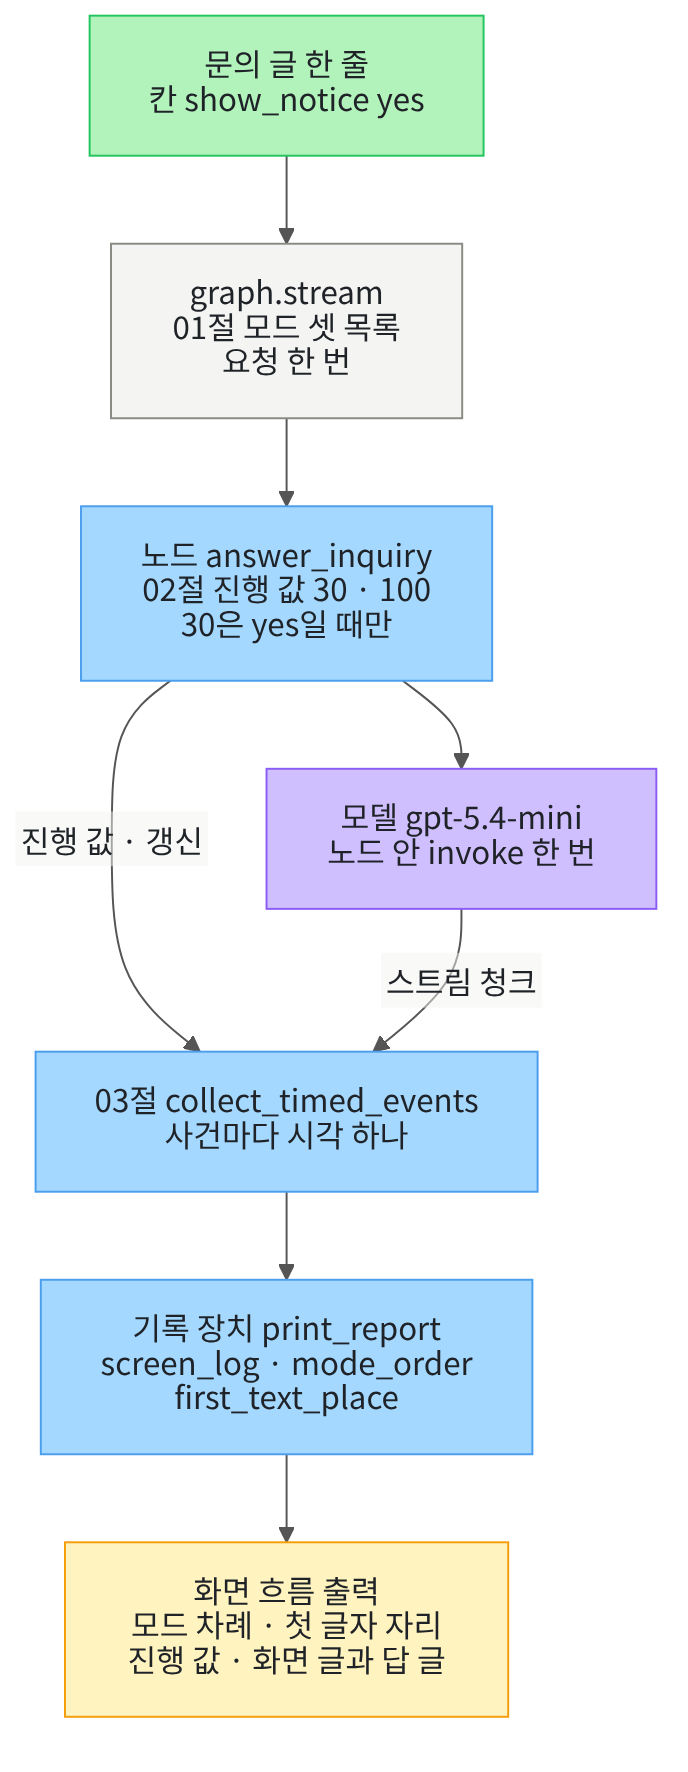

## 1. 준비

이번 절은 이 챕터의 실습입니다.
01절 모드 목록, 02절 진행 값과 스트림 청크 이어 붙이기, 03절 사건마다 시각 적기를 문의 하나에 모읍니다.
첫 셀은 02·03절과 같은 패키지 넷을 설치하고, 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`과 `langgraph: 1.2.11`이 보입니다.
네 판 모두 실습 폴더 잠금과 같은 판입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모델을 만드는 함수 `init_chat_model`은 Ch 6 01절, 상태 형식과 그래프 이름은 Ch 13 01절과 같습니다.
함수 `get_stream_writer`는 01·02절에서 진행 값을 보낼 때 썼습니다.
마지막 가져오기 줄은 앞에서 배운 함수 다섯을 도구 파일 `stream_tools.py`에서 가져옵니다.
이 절에서 새로 배우는 이름은 없습니다.

In [2]:
# 모델(Ch 6 01절)·그래프(Ch 13 01절)를 만드는 이름과, 진행 값을 보낼 쓰기 함수를 가져옵니다
from typing_extensions import TypedDict
from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph, START, END
from langgraph.config import get_stream_writer
# 01~03절에서 배운 함수 다섯은 도구 파일에서 가져옵니다
from stream_tools import collect_timed_events, first_text_place, mode_order, positions_of, three_times

print("도구 파일에서 가져온 함수:", "collect_timed_events, first_text_place, mode_order, positions_of, three_times")

도구 파일에서 가져온 함수: collect_timed_events, first_text_place, mode_order, positions_of, three_times


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: collect_timed_events, first_text_place, mode_order, positions_of, three_times`가 보입니다.
함수 `positions_of`는 01절 노트북 4절, `mode_order`는 02절 노트북 4절에서 처음 적었습니다.
함수 `collect_timed_events`·`first_text_place`·`three_times`는 03절 노트북 3·5·7절에서 처음 적었습니다.

03절 함수 셋은 이 절에서 도구 파일로 옮겼고, 설명 주석과 본문은 03절 셀 글 그대로입니다.
그래서 함수 `three_times` 안 주석의 「5절 함수」는 03절 노트북 5절을 가리킵니다.
함수 `collect_timed_events`가 기능 묶음 `time`을 쓰므로, 도구 파일 맨 위에 `import time` 줄이 생겼습니다.

앞에서 배운 함수는 `stream_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-25에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.

## 2. 오늘 처리할 문의

자료실 홈페이지에 문의 창이 있다고 합시다.
이용자가 문의를 보내면, 창은 답이 다 올 때까지 기다리지 않고 받은 것부터 띄웁니다.
모델에게 요청을 보내기 전에, 「답을 준비하고 있습니다」 같은 진행 표시를 먼저 띄울 수도 있습니다.
이 절은 그 창을 코드로 흉내 내어, 무엇이 언제 화면에 뜨는지 봅니다.
다음 셀은 오늘 처리할 문의 글과 시스템 메시지 글을 정하고, 출처와 함께 출력합니다.

In [5]:
# 오늘 처리할 자료실 문의 글과, 모델에게 줄 시스템 메시지 글을 정합니다
system_text = "자료실 이용 문의에 답하는 안내 도우미입니다. 두 문장의 한국어로 답하세요."
question_text = "빌린 책의 반납 날짜를 늘리려면 어떻게 하나요?"
print("시스템 메시지 글:", system_text)
print("문의 글:", question_text)
print("두 글의 출처: 이 절에서 실행 전에 정한 글(02절 배송 문의를 자료실 문의로 바꿈)")

시스템 메시지 글: 자료실 이용 문의에 답하는 안내 도우미입니다. 두 문장의 한국어로 답하세요.
문의 글: 빌린 책의 반납 날짜를 늘리려면 어떻게 하나요?
두 글의 출처: 이 절에서 실행 전에 정한 글(02절 배송 문의를 자료실 문의로 바꿈)


**결과 읽기** — 출력 줄 `문의 글: 빌린 책의 반납 날짜를 늘리려면 어떻게 하나요?`가 보입니다.
두 글은 이 절에서 실행 전에 정했고, 결과를 보고 바꾸지 않았습니다.
시스템 메시지 글은 02절 글에서 「배송」을 「자료실 이용」으로만 바꿨습니다.
답을 두 문장으로 부탁해, 모델의 답이 짧게 끝나게 했습니다.

## 3. 재료 만들기

먼저 상태 형식을 만듭니다.
칸 `question`과 `answer`는 02절과 같고, 칸 `show_notice`를 하나 더 둡니다.
칸 `show_notice`에는 모델 요청 전에 진행 값을 보낼지를 글 `"yes"`나 `"no"`로 적습니다.
칸 구성이 02절과 달라, 상태 형식에도 새 이름을 붙입니다.

In [6]:
# 문의 글·답 글과, 요청 전 진행 값을 보낼지 적는 칸을 둔 상태 형식입니다(Ch 13 01절 모양, 세 칸 모두 규칙 없음)
class InquiryState(TypedDict):
    question: str
    answer: str
    show_notice: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 문의에 답하는 노드입니다.
02절 노드 `write_answer`와 같은 차례에, 요청 전 진행 값을 보낼지 고르는 `if` 하나를 더했습니다.
칸 `show_notice`가 `"yes"`일 때만 진행 값 30을 보내고, 진행 값 100은 늘 보냅니다.

In [7]:
# 칸 show_notice가 "yes"일 때만 모델 요청 전 진행 값을 보내고, 모델이 쓴 답 글을 칸 answer에 내는 노드입니다
def answer_inquiry(state):
    writer = get_stream_writer()
    if state["show_notice"] == "yes":
        writer({"stage": "before_model", "progress": 30})
    messages = [("system", system_text), ("user", state["question"])]
    # 모델 요청은 이 줄에서 한 번 나가고, 답을 다 받은 뒤에 다음 줄로 갑니다
    response = model.invoke(messages)
    writer({"stage": "after_model", "progress": 100})
    return {"answer": response.text}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
진행 값 딕셔너리 둘은 02절 노드와 같은 값입니다.
칸 `show_notice`는 노드 안에서만 읽고, 모델에게 보내는 메시지 목록에는 넣지 않습니다.

다음 셀은 노드 하나를 START → answer_inquiry → END로 이어, 체크포인터 없이 컴파일합니다.

In [8]:
# 노드 하나를 START → answer_inquiry → END로 잇고, 체크포인터 없이 컴파일합니다
builder = StateGraph(InquiryState)
builder.add_node("answer_inquiry", answer_inquiry)
builder.add_edge(START, "answer_inquiry")
builder.add_edge("answer_inquiry", END)
graph = builder.compile()
print("등록한 노드:", list(builder.nodes))

등록한 노드: ['answer_inquiry']


**결과 읽기** — 출력 줄 `등록한 노드: ['answer_inquiry']`가 보입니다.

## 4. 결과를 볼 기록 장치

화면에 무엇이 뜨는지 보려면, 받은 사건을 화면에 띄울 것으로 바꿔 읽는 장치가 있어야 합니다.
다음 셀의 함수 `screen_log`는 사건을 차례로 읽어, 진행 값은 목록에 모으고 스트림 청크의 글은 이어 붙입니다.
02절 7절에서 스트림 청크의 글을 차례로 이어 붙이던 셀을 함수 하나로 묶은 모양입니다.
글자가 없는 스트림 청크는 빈 글이라, 이어 붙여도 화면의 글이 바뀌지 않습니다.

In [9]:
# 사건을 차례로 읽어, 화면에 띄울 진행 값 목록과 이어 붙인 답 글을 딕셔너리로 내놓습니다
def screen_log(events):
    screen = {"notices": [], "text": ""}
    for mode, data in events:
        if mode == "custom":
            screen["notices"].append(data["progress"])
        # 모드 messages의 자료는 (스트림 청크, 칸 metadata) 짝이라, [0]이 스트림 청크입니다
        if mode == "messages":
            screen["text"] = screen["text"] + data[0].text
    return screen

**결과 읽기** — 정의 셀이라 출력이 없습니다.
키 `notices`에는 진행 값의 `progress`가 받은 차례대로 쌓입니다.
키 `text`에는 스트림 청크의 글이 받은 차례대로 이어 붙습니다.

다음 셀은 실행 기록 하나를 받아, 화면 흐름을 보는 값을 한 줄씩 출력하는 함수입니다.
모드 차례는 02절 함수 `mode_order`로, 글자가 든 첫 스트림 청크의 자리는 03절 함수 `first_text_place`로 봅니다.
마지막 사건인 갱신에 담긴 답 글과, 화면에 이어 붙인 글이 같은지도 봅니다.

In [10]:
# 시각을 적은 실행 기록 하나(collect_timed_events의 결과)에서, 화면 흐름을 보는 값을 한 줄씩 출력합니다
def print_report(run_record):
    events = run_record["events"]
    screen = screen_log(events)
    # 마지막 사건은 노드의 갱신이고, {노드 이름: {칸 이름: 값}} 모양입니다
    final_answer = events[-1][1]["answer_inquiry"]["answer"]
    print("모드 차례:", mode_order(events))
    print("첫 사건의 모드 이름:", events[0][0])
    print("글자가 든 첫 스트림 청크의 자리:", first_text_place(events))
    print("화면에 띄운 진행 값:", screen["notices"])
    print("화면 글과 답 글이 같은가:", screen["text"] == final_answer)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 안에서 앞 셀의 `screen_log`를 부르므로, 앞 셀을 먼저 실행해 두어야 합니다.
자리 `-1`은 03절 6절에서 본 대로 목록의 맨 끝 자리입니다.
답 글이나 초처럼 실행마다 달라지는 값은 이 함수가 출력하지 않습니다.

## 5. 실행 1 · 요청 전 진행 값을 켠 실행

실행 1은 칸 `show_notice`를 `"yes"`로 두고, 02·03절과 같은 모드 셋으로 한 번 실행합니다.
03절 함수 `collect_timed_events`로 사건마다 받은 시각도 함께 적습니다.
실행 전에 예상해 봅니다.
노드가 모델 요청 전에 진행 값을 보내니, 첫 사건은 모드 `custom`의 진행 값 30일 것입니다.

In [11]:
# 실행 1: 요청 전 진행 값을 켜고, 모드 셋을 한 목록으로 골라 한 번 실행합니다(모델 요청 1번)
answer_modes = ["messages", "updates", "custom"]
first_input = {"question": question_text, "answer": "", "show_notice": "yes"}
# 체크포인터가 없어 설정 자리에는 None을 넘깁니다(02·03절과 같음)
first_run = collect_timed_events(graph, first_input, None, answer_modes)
first_events = first_run["events"]
print("받은 사건 수:", len(first_events))
print("사건마다 시각이 하나씩인가:", len(first_events) == len(first_run["times"]))

받은 사건 수: 62
사건마다 시각이 하나씩인가: True


**결과 읽기** — 출력 줄 `사건마다 시각이 하나씩인가: True`가 보입니다.
03절처럼 사건 목록과 시각 목록이 같은 자리끼리 짝을 이룹니다.

이번 실행에서는 출력 줄 `받은 사건 수: 62`입니다.
모델의 답이 몇 개의 스트림 청크로 나뉘어 오느냐에 따라, 이 수는 달라질 수 있습니다.

다음 셀은 앞에서 만든 기록 장치로 실행 1의 화면 흐름을 출력합니다.

In [12]:
# 실행 1의 화면 흐름을 기록 장치로 출력합니다
print_report(first_run)

모드 차례: ['custom', 'messages', 'custom', 'updates']
첫 사건의 모드 이름: custom
글자가 든 첫 스트림 청크의 자리: 3
화면에 띄운 진행 값: [30, 100]
화면 글과 답 글이 같은가: True


**결과 읽기** — 출력 줄 `모드 차례: ['custom', 'messages', 'custom', 'updates']`는 02·03절과 같은 차례입니다.
출력 줄 `첫 사건의 모드 이름: custom`으로, 예상대로 진행 값이 첫 사건이었습니다.
출력 줄 `글자가 든 첫 스트림 청크의 자리: 3`이라, 답의 첫 글자는 셋째 사건에서 화면에 뜹니다.
출력 줄 `화면에 띄운 진행 값: [30, 100]`과 `화면 글과 답 글이 같은가: True`도 보입니다.
화면에 이어 붙인 글은 마지막 갱신의 답 글과 같았습니다.

다음 셀은 첫 사건의 자료와, 화면에 쌓인 답 글을 봅니다.

In [13]:
# 실행 1의 첫 사건 자료를 보고, 화면에 쌓인 답 글을 봅니다(실행마다 달라질 수 있는 글)
print("첫 사건의 자료:", first_events[0][1])
first_screen = screen_log(first_events)
print("화면에 쌓인 답 글:")
print(first_screen["text"])

첫 사건의 자료: {'stage': 'before_model', 'progress': 30}
화면에 쌓인 답 글:
대출 중인 책은 자료실 데스크나 홈페이지의 대출 내역에서 반납 연장 신청을 하시면 됩니다.  
다만 예약이 걸린 책이나 연장 가능 횟수를 초과한 경우에는 연장이 되지 않을 수 있습니다.


**결과 읽기** — 출력 줄 `첫 사건의 자료: {'stage': 'before_model', 'progress': 30}`이 보입니다.
화면은 이 진행 값을 받자마자 「답을 준비하고 있습니다」 같은 표시를 띄울 수 있습니다.
이 사건은 모델 요청 전에 나오므로, 화면이 처음 바뀌기까지 걸린 시간이 첫 사건 시간입니다.

라벨 줄 `화면에 쌓인 답 글:` 아래가 이번 실행에서 화면에 쌓인 답 글입니다.
이번 실행에서는 두 문장이 두 줄로 찍혔고, 실행마다 문장이 달라질 수 있습니다.

## 6. 같은 설정으로 한 번 더

실행 2로 가기 전에, 실행 1과 같은 설정으로 한 번 더 보냅니다.
같은 설정에서도 실행마다 같은 값과 달라지는 값을 먼저 가르려는 것입니다.
실행 전에 예상해 봅니다.
모드 차례와 자리는 노드 코드가 정하니 같고, 사건 수는 달라질 수 있을 것입니다.

In [14]:
# 실행 1과 같은 설정으로 한 번 더 실행하고, 기록 장치로 화면 흐름을 봅니다(모델 요청 1번)
again_run = collect_timed_events(graph, first_input, None, answer_modes)
again_events = again_run["events"]
print_report(again_run)

모드 차례: ['custom', 'messages', 'custom', 'updates']
첫 사건의 모드 이름: custom
글자가 든 첫 스트림 청크의 자리: 3
화면에 띄운 진행 값: [30, 100]
화면 글과 답 글이 같은가: True


**결과 읽기** — 기록 장치의 다섯 출력 줄이 실행 1과 같습니다.
출력 줄 `글자가 든 첫 스트림 청크의 자리: 3`과 `화면에 띄운 진행 값: [30, 100]`이 다시 보입니다.

다음 셀은 두 실행의 모드 차례와 받은 사건 수를 견줍니다.

In [15]:
# 같은 설정으로 보낸 두 실행의 모드 차례와 받은 사건 수를 견줍니다
print("두 실행의 모드 차례가 같은가:", mode_order(first_events) == mode_order(again_events))
print("두 실행의 받은 사건 수:", len(first_events), len(again_events))

두 실행의 모드 차례가 같은가: True
두 실행의 받은 사건 수: 62 60


**결과 읽기** — 출력 줄 `두 실행의 모드 차례가 같은가: True`가 보입니다.

이번 실행에서는 출력 줄 `두 실행의 받은 사건 수: 62 60`으로, 사건 수가 두 실행에서 달랐습니다.
설정이 같아도 사건 수는 달라질 수 있어, 사건 수의 차이는 설정 탓으로 읽지 않습니다.

## 7. 실행 2 · 요청 전 진행 값만 끈 실행

값 하나만 바꿔 봅니다.
바꿀 값은 칸 `show_notice`이고, `"yes"`를 `"no"`로 바꿉니다.
문의 글, 노드, 모드 목록은 실행 1과 같습니다.
실행 전에 예상해 봅니다.
진행 값 30이 없으니 첫 사건은 모드 `messages`의 스트림 청크이고, 진행 값은 100 하나만 올 것입니다.

다음 셀은 같은 문의로 그래프를 한 번 더 실행합니다(모델 요청 1번).

In [16]:
# 실행 2: 칸 show_notice 하나만 "no"로 바꿔, 같은 문의로 한 번 더 실행합니다(모델 요청 1번)
second_input = {"question": question_text, "answer": "", "show_notice": "no"}
second_run = collect_timed_events(graph, second_input, None, answer_modes)
second_events = second_run["events"]
print("받은 사건 수:", len(second_events))
print("사건마다 시각이 하나씩인가:", len(second_events) == len(second_run["times"]))

받은 사건 수: 60
사건마다 시각이 하나씩인가: True


**결과 읽기** — 출력 줄 `사건마다 시각이 하나씩인가: True`가 보입니다.

이번 실행에서는 출력 줄 `받은 사건 수: 60`입니다.
실행 1과 같은 문의라도, 이 수는 실행마다 달라질 수 있습니다.

다음 셀은 같은 기록 장치로 실행 2의 화면 흐름을 출력합니다.

In [17]:
# 실행 2의 화면 흐름을 기록 장치로 출력합니다
print_report(second_run)

모드 차례: ['messages', 'custom', 'updates']
첫 사건의 모드 이름: messages
글자가 든 첫 스트림 청크의 자리: 2
화면에 띄운 진행 값: [100]
화면 글과 답 글이 같은가: True


**결과 읽기** — 출력 줄 `모드 차례: ['messages', 'custom', 'updates']`가 보입니다.
맨 앞의 `custom`이 빠졌고, 예상대로 첫 사건의 모드가 `messages`로 바뀌었습니다.
출력 줄 `글자가 든 첫 스트림 청크의 자리: 2`는 실행 1보다 한 자리 앞입니다.
출력 줄 `화면에 띄운 진행 값: [100]`이라, 화면에는 모델 요청 뒤의 진행 값만 떴습니다.
출력 줄 `화면 글과 답 글이 같은가: True`는 실행 1과 같습니다.

다음 셀은 실행 2의 첫 사건이 어떤 스트림 청크인지와, 진행 값이 나온 자리를 봅니다.

In [18]:
# 실행 2의 첫 사건 스트림 청크와, 진행 값이 나온 자리를 봅니다(01절 함수 positions_of)
second_first = second_events[0][1]
print("첫 사건 스트림 청크의 글자 수:", len(second_first[0].text))
notice_places = positions_of(second_events, "custom")
print("진행 값의 자리가 마지막 사건 바로 앞인가:", notice_places == [len(second_events) - 1])

첫 사건 스트림 청크의 글자 수: 0
진행 값의 자리가 마지막 사건 바로 앞인가: True


**결과 읽기** — 출력 줄 `첫 사건 스트림 청크의 글자 수: 0`이 보입니다.
02절 5절에서 본 글자 없는 첫 스트림 청크가, 이번에는 첫 사건이 되었습니다.
이 사건을 받아도 화면의 글은 바뀌지 않고, 자리 2의 첫 글자에서 화면이 처음 바뀝니다.
출력 줄 `진행 값의 자리가 마지막 사건 바로 앞인가: True`로, 진행 값 100은 스트림 청크를 다 받은 뒤에 왔습니다.

## 8. 세 실행 견주기

세 실행을 한 표로 놓고, 무엇이 설정 탓으로 달라졌는지 봅니다.
실행 1과 같은 설정 다시 사이에서 달라진 값은, 설정이 같아도 달라지는 값입니다.
실행 1과 실행 2 사이에서만 달라진 값을, 칸 `show_notice`를 바꾼 탓으로 읽습니다.
다음 셀은 세 실행의 첫 사건 모드, 글자가 든 첫 스트림 청크의 자리, 진행 값 수를 한 줄씩 출력합니다.

In [19]:
# 세 실행의 첫 사건 모드, 글자가 든 첫 스트림 청크의 자리, 진행 값 수를 한 줄씩 견줍니다
runs = {"실행 1": first_run, "같은 설정 다시": again_run, "실행 2": second_run}
print("실행 | 첫 사건 | 글자가 든 첫 스트림 청크 자리 | 진행 값 수")
for name in runs:
    events = runs[name]["events"]
    notices = positions_of(events, "custom")
    print(name, "|", events[0][0], "|", first_text_place(events), "|", len(notices))

실행 | 첫 사건 | 글자가 든 첫 스트림 청크 자리 | 진행 값 수
실행 1 | custom | 3 | 2
같은 설정 다시 | custom | 3 | 2
실행 2 | messages | 2 | 1


**결과 읽기** — 라벨 줄 `실행 | 첫 사건 | 글자가 든 첫 스트림 청크 자리 | 진행 값 수` 아래 세 줄이 세 실행입니다.
줄 `실행 1 | custom | 3 | 2`와 `같은 설정 다시 | custom | 3 | 2`는 같습니다.
줄 `실행 2 | messages | 2 | 1`만 세 값이 모두 다릅니다.
그래서 이 세 값의 차이는 칸 `show_notice`를 바꾼 탓으로 읽습니다.

다음 셀은 세 실행의 받은 사건 수와 세 시간(초)을 한 줄씩 출력합니다.

In [20]:
# 세 실행의 받은 사건 수와 세 시간(초)을 한 줄씩 견줍니다(03절 함수 three_times)
print("실행 | 사건 수 | 첫 사건 시간 | 첫 토큰 도착 시간 | 전체 걸린 시간")
for name in runs:
    seconds = three_times(runs[name])
    count = len(runs[name]["events"])
    print(name, "|", count, "|", seconds["첫 사건 시간"], "|", seconds["첫 토큰 도착 시간"], "|", seconds["전체 걸린 시간"])

실행 | 사건 수 | 첫 사건 시간 | 첫 토큰 도착 시간 | 전체 걸린 시간
실행 1 | 62 | 0.003 | 0.666 | 1.055
같은 설정 다시 | 60 | 0.003 | 0.699 | 1.131
실행 2 | 60 | 0.537 | 0.568 | 0.96


**결과 읽기** — 라벨 줄 `실행 | 사건 수 | 첫 사건 시간 | 첫 토큰 도착 시간 | 전체 걸린 시간` 아래 세 줄이 세 실행입니다.
사건 수와 초는 같은 설정으로 보낸 두 실행 사이에서도 달라질 수 있는 값입니다.
그래서 세 실행의 초를 견주어 어느 설정이 빠르다고 말하지 않습니다.

이번 실행에서는 줄 `실행 1 | 62 | 0.003 | 0.666 | 1.055`와 `실행 2 | 60 | 0.537 | 0.568 | 0.96`입니다.
실행 2의 첫 사건은 모델이 보낸 스트림 청크라, 첫 사건 시간에 모델을 기다린 시간이 들어 있습니다.
줄 `같은 설정 다시 | 60 | 0.003 | 0.699 | 1.131`의 첫 토큰 도착 시간과 전체 걸린 시간도 실행 1과 달랐습니다.

## 정리

1. 모드 목록, 진행 값, 스트림 청크 이어 붙이기, 사건마다 시각 적기를 그래프 하나에 모아 문의 창 화면을 흉내 냈습니다.
2. 요청 전 진행 값을 켠 실행은 첫 사건이 진행 값 30이었고, 같은 설정으로 다시 보내도 모드 차례와 자리가 같았습니다.
3. 진행 값 하나만 끄자 첫 사건이 글자 없는 스트림 청크가 되어, 화면은 자리 2의 첫 글자에서 처음 바뀌었습니다.

이 절로 Ch 25가 끝납니다.
Ch 26 01절에서는 전문 에이전트를 도구로 감싸 일을 맡기는 위임 구조를 다룹니다.